# Parte IV — Invertendo símbolos discretos com classificação

**DAS410116 — Inteligência Artificial Generativa · UFSC · 2026/2**
**Professor:** Eric A. Antonelo
**Aluno:** Leonardo Coli
**Fontes e uso de IA:** Claude.

Os valores escalares da regressão viram símbolos discretos representados por vetores one-hot. Queries e keys continuam dependendo só da posição.

Não há dimensão de batch. A matriz de atenção **não** é alvo de treino: a loss é a NLL dos símbolos de saída.

## 0. Configuração

In [1]:
import math
from pathlib import Path

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_printoptions(precision=3, sci_mode=False)

## 1. Atenção posicional

Mesmas features posicionais e mesma função de atenção da Parte III.

In [2]:
def positional_features(L, device=None):
    # 1.1: [1, p, p^2] com p_i = -1 + 2i/(L-1)
    i = torch.arange(L, dtype=torch.float32, device=device).unsqueeze(1)
    p = -1.0 + 2.0 * i / (L - 1)
    return torch.cat([torch.ones_like(p), p, p**2], dim=1)


def compute_attention_weights(Q, K, mask=None, logit_scale=1.0):
    # 1.2: softmax(s * Q K^T / sqrt(d_k)) nas keys, com máscara opcional
    d_k = Q.shape[-1]
    scores = logit_scale * (Q @ K.T) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    return torch.softmax(scores, dim=-1)

## 2. Values one-hot — 0,40 ponto

Vocabulário com $C=12$ símbolos. No primeiro experimento, a amostragem é sem reposição, então todo símbolo de uma
sequência é único.

In [3]:
vocab_size = 12
L = 6

tokens = torch.randperm(vocab_size)[:L]

# 2.1: tokens em vetores one-hot float
values = F.one_hot(tokens, num_classes=vocab_size).float()

# 2.2: alvo da classificação = sequência invertida
target_tokens = torch.flip(tokens, dims=[0])

print("Tokens de entrada:", tokens)
print("Values one-hot:")
print(values)
print("Tokens alvo:", target_tokens)

# 2.3: shapes
print(
    "\nshapes -> tokens:",
    tuple(tokens.shape),
    "| values:",
    tuple(values.shape),
    "| target_tokens:",
    tuple(target_tokens.shape),
)

Tokens de entrada: tensor([3, 4, 0, 5, 7, 9])
Values one-hot:
tensor([[0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.]])
Tokens alvo: tensor([9, 7, 5, 0, 4, 3])

shapes -> tokens: (6,) | values: (6, 12) | target_tokens: (6,)


### Resposta escrita 2

**Perguntas**

1. Por que `values` tem shape `(L, vocab_size)`?
2. Por que a identidade do símbolo fica em $V$, enquanto $Q$ e $K$ carregam a informação de posição?
3. Por que símbolos únicos deixam o alinhamento aprendido mais fácil de interpretar?

**Respostas**

1. Há uma linha por posição da sequência e uma coluna por símbolo do vocabulário. A linha $j$ é o vetor one-hot de
   $t_j$ em $\mathbb R^{C}$, com $C=12$ fixo qualquer que seja $L$. No exemplo, $L=6$ dá `(6, 12)`.

2. A tarefa se separa em duas perguntas.
   - **De onde ler.** A resposta depende só da posição: a saída $i$ lê a entrada $L-1-i$, quaisquer que sejam os
     símbolos. Isso fica em $Q$ e $K$.
   - **O que escrever.** A resposta é o símbolo que está lá. Isso fica em $V$.

   A saída $\widehat P=AV$ copia, ou mistura, as linhas one-hot escolhidas pelo roteamento, e como $A$ é estocástica
   por linhas, $\widehat P$ já sai como distribuição. Se os símbolos entrassem em $Q$ e $K$, o roteamento passaria a
   depender do conteúdo e mudaria a cada sequência. O modelo teria de aprender a ignorar justamente essa informação.

3. Com símbolos únicos, cada categoria ocupa uma única posição, então
   $\widehat P_{i,c}=\sum_jA_{ij}\mathbb 1[t_j=c]=A_{i,j(c)}$. A probabilidade dada ao alvo é **exatamente** o peso de
   atenção na posição de origem correta, e a NLL vira $-\frac1L\sum_i\log A_{i,L-1-i}$. Acertar o símbolo implica ter
   olhado para o lugar certo, porque a correspondência entre categoria e posição é um para um. Com repetição, a massa
   de posições diferentes com o mesmo símbolo se soma em $\widehat P$, e a saída não diz mais qual ocorrência foi lida.

## 3. Modelo treinável

A saída

$$\widehat P=AV$$

tem shape $(L,C)$. Toda linha de $A$ soma um e toda linha de $V$ é one-hot, então cada linha de $\widehat P$ é uma
distribuição categórica: $\widehat P_{ic}=\sum_j A_{ij}\,\mathbb 1[t_j=c]$ é a massa de atenção que a posição de saída
$i$ coloca nas posições de entrada que contêm o símbolo $c$.

In [4]:
d_position = 3
d_k = 8

W_Q = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
W_K = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
logit_scale = torch.nn.Parameter(torch.tensor(math.log(10.0)))

# 3.1: forward no exemplo acima (modelo não treinado)
positions = positional_features(L)
Q = positions @ W_Q
K = positions @ W_K
A = compute_attention_weights(Q, K, logit_scale=logit_scale.exp())
probabilities = A @ values

# 3.2: cada linha de probabilities soma 1 e é não negativa
row_sums = probabilities.sum(dim=-1)
assert torch.allclose(row_sums, torch.ones(L), atol=1e-6)
assert bool((probabilities >= 0).all())
print("probabilities:", tuple(probabilities.shape))
print("somas das linhas:", row_sums.detach())

probabilities: (6, 12)
somas das linhas: tensor([1.000, 1.000, 1.000, 1.000, 1.000, 1.000])


## 4. Objetivo categórico — 0,70 ponto

Treino em todos os comprimentos de 4 a 8. Para cada comprimento, as sequências são sorteadas sem reposição, e a
loss do passo é a média das NLLs de $5\times16=80$ sequências. É um modelo novo, com parâmetros independentes dos
da Parte III.

In [5]:
train_lengths = range(4, 9)
n_sequences_per_length = 16
n_steps = 5000

optimizer = torch.optim.Adam([W_Q, W_K, logit_scale], lr=0.02)

raw_loss_history = []
smooth_loss_history = []
ema = None

for step in range(n_steps):
    losses = []

    for L in train_lengths:
        # 4.1: positions, Q, K, escala positiva e A (uma vez por comprimento)
        positions = positional_features(L)
        Q = positions @ W_Q
        K = positions @ W_K
        scale = logit_scale.exp()
        A = compute_attention_weights(Q, K, logit_scale=scale)

        for _ in range(n_sequences_per_length):
            # 4.2: tokens únicos e values one-hot
            tokens = torch.randperm(vocab_size)[:L]
            values = F.one_hot(tokens, num_classes=vocab_size).float()

            # 4.3: probabilidades categóricas e alvos invertidos
            probabilities = A @ values
            target_tokens = torch.flip(tokens, dims=[0])

            # 4.4: NLL das saídas; A não é comparada com nenhum alvo
            losses.append(F.nll_loss(torch.log(probabilities + 1e-8), target_tokens))

    # 4.5: média, backprop e atualização
    loss = torch.stack(losses).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 4.6: loss bruta e EMA com coeficiente 0.98
    raw_loss_history.append(loss.item())
    ema = loss.item() if ema is None else 0.98 * ema + 0.02 * loss.item()
    smooth_loss_history.append(ema)

    if step % 500 == 0 or step == n_steps - 1:
        print(
            f"step={step:4d}  loss={loss.item():.3e}  ema={ema:.3e}  s={logit_scale.exp().item():.2f}"
        )

step=   0  loss=1.715e+00  ema=1.715e+00  s=10.20


step= 500  loss=1.473e-04  ema=3.060e-04  s=60.89


step=1000  loss=3.435e-05  ema=3.865e-05  s=67.64


step=1500  loss=1.430e-05  ema=1.544e-05  s=71.60


step=2000  loss=7.430e-06  ema=7.891e-06  s=74.51


step=2500  loss=4.289e-06  ema=4.515e-06  s=76.94


step=3000  loss=2.723e-06  ema=2.838e-06  s=78.90


step=3500  loss=1.752e-06  ema=1.841e-06  s=80.80


step=4000  loss=1.098e-06  ema=1.161e-06  s=82.92


step=4500  loss=5.454e-07  ema=5.862e-07  s=86.62


step=4999  loss=2.980e-07  ema=3.154e-07  s=89.62


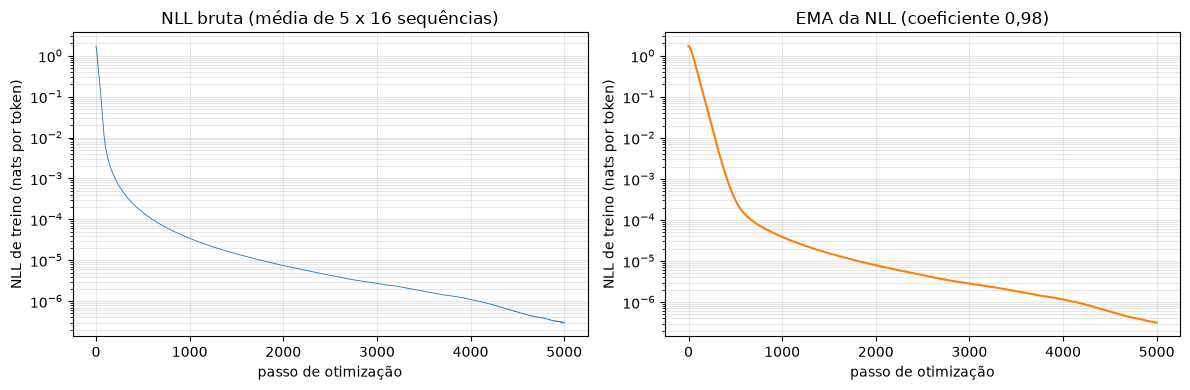

s final = 89.62


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 4.7: NLL bruta e EMA, escala log
axes[0].plot(raw_loss_history, linewidth=0.6)
axes[0].set_title("NLL bruta (média de 5 x 16 sequências)")
axes[1].plot(smooth_loss_history, color="tab:orange")
axes[1].set_title("EMA da NLL (coeficiente 0,98)")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("passo de otimização")
    ax.set_ylabel("NLL de treino (nats por token)")
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()
print(f"s final = {logit_scale.exp().item():.2f}")

**Observação.** A curva de NLL bruta não tem ruído, ao contrário da MSE da Parte III. Com símbolos únicos, a
probabilidade do alvo é exatamente o peso de atenção na posição de origem, $\widehat P_{i,t}=A_{i,L-1-i}$, então a
loss é determinística em $A$: não depende de quais símbolos foram sorteados. Por isso as 16 sequências por
comprimento não reduzem variância nenhuma aqui; elas foram mantidas porque o enunciado pede.

### Por que não `F.cross_entropy(probabilities, target_tokens)`: verificação numérica

A célula compara as duas chamadas numa distribuição já bem treinada e numa distribuição perfeita (one-hot).

In [7]:
target = torch.tensor([2])
for name, probs in [
    ("confiante (0.9 no alvo)", torch.tensor([[0.05, 0.05, 0.90]])),
    ("perfeita (1.0 no alvo)", torch.tensor([[0.0, 0.0, 1.0]])),
]:
    nll = F.nll_loss(torch.log(probs + 1e-8), target).item()
    ce_wrong = F.cross_entropy(probs, target).item()
    print(
        f"{name:<24} nll_loss(log p) = {nll:.4f} | cross_entropy(p) = {ce_wrong:.4f} | "
        f"softmax(p) = {torch.softmax(probs, dim=-1).numpy().round(3)}"
    )

# Com C = 12, nem a distribuição perfeita consegue loss zero na chamada errada
perfect12 = F.one_hot(torch.tensor([0]), num_classes=vocab_size).float()
print(
    f"\nC = 12, distribuição perfeita: cross_entropy(p) = {F.cross_entropy(perfect12, torch.tensor([0])).item():.4f}"
    f" (uniforme daria log 12 = {math.log(vocab_size):.4f})"
)

# cross_entropy só fica correta se receber logits; log p é um conjunto válido de logits
probs = torch.tensor([[0.05, 0.05, 0.90]])
print(
    "\ncross_entropy(log p) == nll_loss(log p):",
    torch.isclose(
        F.cross_entropy(torch.log(probs), target), F.nll_loss(torch.log(probs), target)
    ).item(),
)

confiante (0.9 no alvo)  nll_loss(log p) = 0.1054 | cross_entropy(p) = 0.6178 | softmax(p) = [[0.23  0.23  0.539]]
perfeita (1.0 no alvo)   nll_loss(log p) = 0.0000 | cross_entropy(p) = 0.5514 | softmax(p) = [[0.212 0.212 0.576]]

C = 12, distribuição perfeita: cross_entropy(p) = 1.6187 (uniforme daria log 12 = 2.4849)

cross_entropy(log p) == nll_loss(log p): True


### Resposta escrita 4

**Pergunta.** Por que a chamada `F.cross_entropy(probabilities, target_tokens)` é inadequada aqui? A resposta deve
distinguir logits de probabilidades normalizadas.

**Resposta**

`F.cross_entropy(z, y)` calcula $-\log\operatorname{softmax}(z)_y$: ela espera **logits** (escores sem normalização,
em $\mathbb R$) e aplica o log-softmax internamente, de forma estável. Aqui `probabilities` já é uma distribuição
normalizada, porque cada linha de $AV$ soma 1. Passá-la para `cross_entropy` aplicaria um **segundo** softmax sobre
números em $[0,1]$. Como $e^0=1$ e $e^1\approx2{,}7$, $\operatorname{softmax}(p)$ fica perto da uniforme, e a célula de
verificação mostra o efeito:
- a distribuição perfeita $(0,0,1)$ vira $(0{,}21;\,0{,}21;\,0{,}58)$ e dá loss 0,551 em vez de 0;
- com $C=12$, a melhor loss possível é 1,62, contra $\log12=2{,}48$ para a uniforme.

A loss deixa de ser a log-verossimilhança do modelo: ela não chega a zero nem quando a previsão é perfeita e mede uma
distribuição que o modelo não produz. O certo é o que o enunciado usa:
`F.nll_loss(torch.log(probabilities + 1e-8), target)`, que já recebe log-probabilidades. Seria equivalente chamar
`cross_entropy(torch.log(p), y)`, porque $\log p$ é um conjunto válido de logits ($\operatorname{softmax}(\log p)=p$);
a célula confirma que as duas dão o mesmo valor. O `1e-8` é indispensável: as classes que não aparecem na sequência têm probabilidade exatamente 0 (coluna nula em
$V$). A `nll_loss` só lê a classe-alvo, então o valor da loss ficaria finito, mas o backward de $\log$ em 0 dá NaN,
que contaminaria o gradiente de $A$.

## 5. Avaliação da classificação — 0,55 ponto

Avaliação em `L = 4, 8, 12` com NLL média, acurácia por token, acurácia de sequência exata e acurácia de alinhamento
pós-treino, além da fração de sequências que têm algum símbolo repetido.

In [8]:
@torch.no_grad()
def evaluate_classification(L, n_sequences=256, repeated_symbols=False, params=None):
    W_Q_, W_K_, logit_scale_ = params if params is not None else (W_Q, W_K, logit_scale)

    # 5.1: A uma vez para este comprimento
    positions = positional_features(L)
    A = compute_attention_weights(
        positions @ W_Q_, positions @ W_K_, logit_scale=logit_scale_.exp()
    )
    expected_source = torch.arange(L - 1, -1, -1)
    row_points_to_source = (
        A.argmax(dim=-1) == expected_source
    )  # (L,), depende só da posição

    losses = []
    token_correct = 0
    token_total = 0
    sequence_correct = 0
    sequences_with_repeats = 0
    example = None

    for _ in range(n_sequences):
        # 5.2: sem reposição (únicos) ou com reposição (randint)
        if repeated_symbols:
            tokens = torch.randint(0, vocab_size, (L,))
        else:
            tokens = torch.randperm(vocab_size)[:L]
        sequences_with_repeats += int(tokens.unique().numel() < L)

        # 5.3: values, probabilidades, alvos e predições
        values = F.one_hot(tokens, num_classes=vocab_size).float()
        probabilities = A @ values
        target_tokens = torch.flip(tokens, dims=[0])
        predictions = probabilities.argmax(dim=-1)

        # 5.4: NLL, tokens corretos e sequência exata
        losses.append(F.nll_loss(torch.log(probabilities + 1e-8), target_tokens))
        correct = predictions == target_tokens
        token_correct += int(correct.sum())
        token_total += L
        sequence_correct += int(correct.all())
        if example is None or (
            repeated_symbols and tokens.unique().numel() < L and example["unique"]
        ):
            example = {
                "tokens": tokens,
                "target": target_tokens,
                "prediction": predictions,
                "unique": tokens.unique().numel() == L,
            }

    # 5.5: alinhamento pós-treino pelo argmax das posições
    alignment_accuracy = row_points_to_source.float().mean().item()

    # 5.6: métricas e A
    return {
        "L": L,
        "nll": torch.stack(losses).mean().item(),
        "token_accuracy": token_correct / token_total,
        "sequence_accuracy": sequence_correct / n_sequences,
        "alignment_accuracy": alignment_accuracy,
        "frac_with_repeats": sequences_with_repeats / n_sequences,
        "attention": A,
        "example": example,
    }


def print_table(rows, title):
    print(title)
    print(
        f"{'L':>3} | {'NLL média':>9} | {'acurácia por token':>18} | {'sequência exata':>15} | "
        f"{'alinhamento':>11} | {'seq. com repetição':>18}"
    )
    print("-" * 89)
    for r in rows:
        print(
            f"{r['L']:>3} | {r['nll']:>9.2e} | {r['token_accuracy']:>18.1%} | {r['sequence_accuracy']:>15.1%} | "
            f"{r['alignment_accuracy']:>11.1%} | {r['frac_with_repeats']:>18.1%}"
        )
    print()


torch.manual_seed(2024)
unique_results = [
    evaluate_classification(L, repeated_symbols=False) for L in [4, 8, 12]
]

# 5.7: tabela com todas as métricas
print_table(unique_results, "Símbolos únicos (sem reposição)")

Símbolos únicos (sem reposição)
  L | NLL média | acurácia por token | sequência exata | alinhamento | seq. com repetição
-----------------------------------------------------------------------------------------
  4 |  0.00e+00 |             100.0% |          100.0% |      100.0% |               0.0%
  8 |  1.49e-06 |             100.0% |          100.0% |      100.0% |               0.0%
 12 |  6.31e-03 |             100.0% |          100.0% |      100.0% |               0.0%



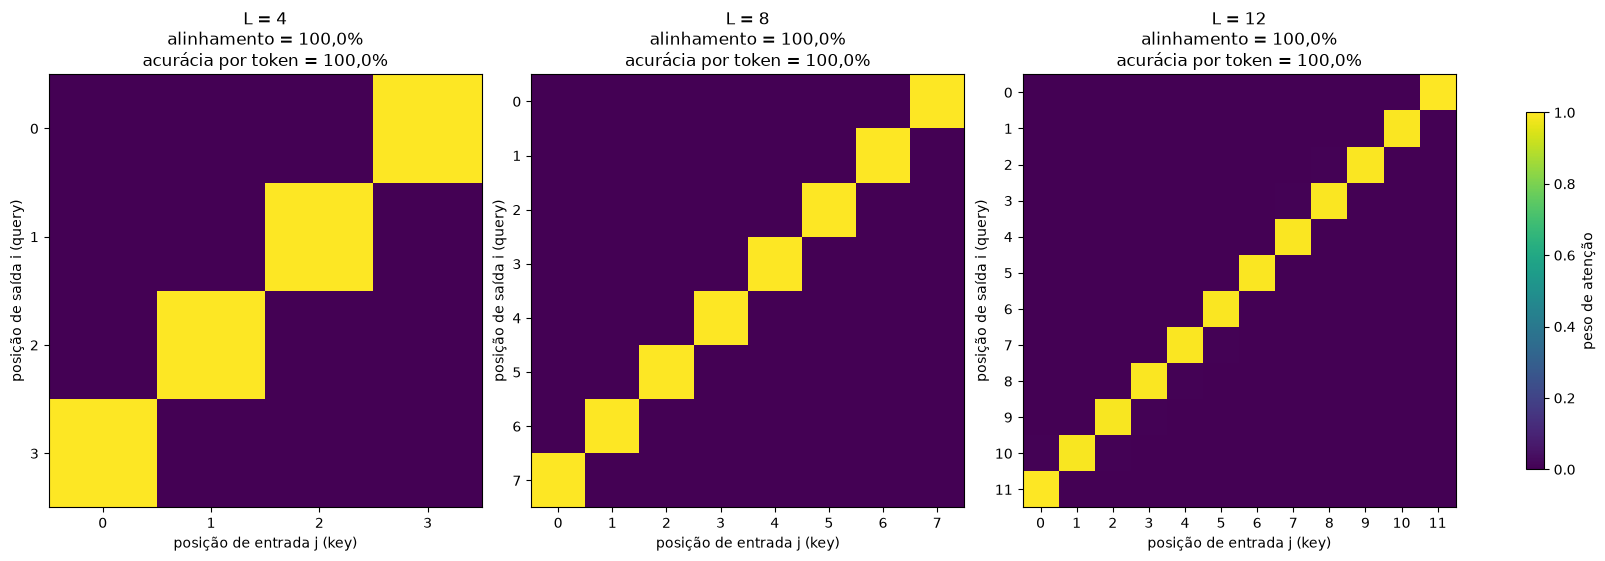

L= 4: peso médio na posição correta = 1.000
L= 8: peso médio na posição correta = 1.000
L=12: peso médio na posição correta = 0.994


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)

# 5.8: matrizes aprendidas para L = 4, 8 e 12, mesma escala de cor
for ax, r in zip(axes, unique_results):
    L = r["L"]
    im = ax.imshow(r["attention"].numpy(), vmin=0, vmax=1, cmap="viridis")
    ax.set_title(
        f"L = {L}\nalinhamento = {r['alignment_accuracy']:.1%}\nacurácia por token = {r['token_accuracy']:.1%}".replace(
            ".", ","
        )
    )
    ax.set_xlabel("posição de entrada j (key)")
    ax.set_ylabel("posição de saída i (query)")
    ax.set_xticks(range(L))
    ax.set_yticks(range(L))

fig.colorbar(im, ax=axes, shrink=0.8, label="peso de atenção")
plt.show()

for r in unique_results:
    A_r = r["attention"]
    print(
        f"L={r['L']:>2}: peso médio na posição correta = "
        f"{A_r[torch.arange(r['L']), torch.arange(r['L'] - 1, -1, -1)].mean().item():.3f}"
    )

## 6. Ambiguidade com símbolos repetidos — 0,35 ponto

Agora os símbolos são sorteados com reposição (`torch.randint`), então a mesma categoria pode aparecer em várias
posições de entrada. O modelo é o mesmo, sem novo treino.

In [10]:
torch.manual_seed(2024)
repeated_results = [
    evaluate_classification(L, repeated_symbols=True) for L in [4, 8, 12]
]

# 6.1: métricas lado a lado
print_table(unique_results, "Símbolos únicos (sem reposição)")
print_table(repeated_results, "Símbolos com repetição (torch.randint)")

print(
    f"{'L':>3} | {'acur. token únicos':>18} | {'acur. token repetidos':>21} | {'alinham. únicos':>15} | {'alinham. repetidos':>18}"
)
print("-" * 86)
for u, r in zip(unique_results, repeated_results):
    print(
        f"{u['L']:>3} | {u['token_accuracy']:>18.1%} | {r['token_accuracy']:>21.1%} | "
        f"{u['alignment_accuracy']:>15.1%} | {r['alignment_accuracy']:>18.1%}"
    )

print("\nExemplos com repetição:")
for r in repeated_results:
    ex = r["example"]
    print(f"L={r['L']:>2}  entrada  = {ex['tokens'].tolist()}")
    print(f"      alvo     = {ex['target'].tolist()}")
    print(f"      predição = {ex['prediction'].tolist()}")

Símbolos únicos (sem reposição)
  L | NLL média | acurácia por token | sequência exata | alinhamento | seq. com repetição
-----------------------------------------------------------------------------------------
  4 |  0.00e+00 |             100.0% |          100.0% |      100.0% |               0.0%
  8 |  1.49e-06 |             100.0% |          100.0% |      100.0% |               0.0%
 12 |  6.31e-03 |             100.0% |          100.0% |      100.0% |               0.0%

Símbolos com repetição (torch.randint)
  L | NLL média | acurácia por token | sequência exata | alinhamento | seq. com repetição
-----------------------------------------------------------------------------------------
  4 |  0.00e+00 |             100.0% |          100.0% |      100.0% |              42.2%
  8 |  1.36e-06 |             100.0% |          100.0% |      100.0% |              95.7%
 12 |  5.82e-03 |             100.0% |          100.0% |      100.0% |             100.0%

  L | acur. token únicos | 

### Resposta escrita 6

**Perguntas**

1. Por que a categoria correta pode ser prevista mesmo quando a ocorrência de origem é ambígua?
2. A acurácia por token pode ser maior que a acurácia de alinhamento quando há repetição?
3. Uma acurácia por token alta prova sozinha que o modelo aprendeu inversão posicional?
4. Compare a acurácia por token e a acurácia de sequência exata.

**Respostas**

1. **Porque a saída soma a massa por categoria, não por posição.** $\widehat P_{ic}=\sum_jA_{ij}\mathbb 1[t_j=c]$
   junta todas as posições que contêm $c$. Se a fonte verdadeira e outra posição têm o mesmo símbolo, qualquer divisão
   da atenção entre elas dá a mesma categoria, e prever o símbolo não exige saber qual ocorrência foi lida. Isso aparece
   até no modelo bem treinado. Em $L=12$, a NLL foi um pouco menor com repetição ($5{,}82\times10^{-3}$) do que com
   símbolos únicos ($6{,}31\times10^{-3}$): parte da massa que vaza para os vizinhos cai em posições com o mesmo
   símbolo do alvo e conta a favor dele.

2. **Pode, mas não aconteceu nos comprimentos pedidos.** O alinhamento conta as linhas cujo argmax de **posição** está
   certo. A acurácia por token conta a **categoria**. Se o argmax de uma linha apontasse para uma posição errada que tem
   o mesmo símbolo da fonte, o token sairia certo e o alinhamento, errado.
   - **No modelo treinado, as duas coincidem.** Em $L=4$, 8 e 12 o argmax de $A$ está certo em todas as linhas, então
     ficam token = alinhamento = 100% nos dois experimentos.
   - **O alinhamento é idêntico entre únicos e repetidos por construção.** $A$ depende só da posição, então trocar a
     forma de sortear os símbolos não muda nada nela.

3. **Não.** A acurácia por token depende da atenção **e** dos dados. Com repetições ou simetrias, um roteamento que não
   inverte pode acertar muito. Por exemplo, uma atenção identidade, que só copia a entrada, acertaria todos os tokens de
   uma sequência palíndroma sem inverter nada. Evidência de inversão posicional exige mais:
   - o teste com símbolos únicos, em que categoria e posição se correspondem um a um;
   - a inspeção de $A$, pelo alinhamento e pelo heatmap;
   - comprimentos variados.

   O modelo treinado passa nos três: 100% de token e de alinhamento com símbolos únicos em $L=4$, 8 e 12, e um
   heatmap anti-diagonal.

4. **A sequência exata é bem mais exigente.** Ela só conta se os $L$ tokens estiverem todos certos. Se cada token
   acertasse com probabilidade 0,99, de forma independente, uma sequência de 12 tokens sairia inteira certa só em
   cerca de 89% das vezes ($0{,}99^{12}$). Aqui as duas métricas ficaram em 100% em $L=4$, 8 e 12, então a diferença não
   aparece. Ela apareceria em comprimentos maiores, em que a atenção fica mais difusa: a métrica por token esconderia
   quão raro é acertar a sequência inteira.

## Extensão opcional — reaproveitando a atenção treinada por regressão

Se a matriz de atenção aprendida na Parte III implementa de fato inversão posicional, ela também deve inverter
values one-hot sem nenhum treino adicional. Os parâmetros da Parte III vêm de `part3_params.pt`, salvo pelo
notebook 3. Se o arquivo não existir (por exemplo, quando este notebook roda sozinho), a célula refaz o treino da
Parte III com o mesmo código, a mesma seed e a mesma ordem de sorteios, o que reproduz os mesmos parâmetros em CPU.
Só os quatro notebooks são enviados, sem o `part3_params.pt`; sem o arquivo, esta célula leva de 1 a 2 minutos a
mais em CPU.

In [11]:
def train_part3_regression():
    # Cópia fiel do treino da Parte III (seed 7, mesma ordem de chamadas ao gerador aleatório)
    torch.manual_seed(7)
    W_Q3 = torch.nn.Parameter(torch.randn(3, 8) * 0.1)
    W_K3 = torch.nn.Parameter(torch.randn(3, 8) * 0.1)
    s3 = torch.nn.Parameter(torch.tensor(math.log(10.0)))
    _ = torch.randn(6, 1)  # o x de demonstração de shapes da Parte III
    opt = torch.optim.Adam([W_Q3, W_K3, s3], lr=0.02)
    for _ in range(5000):
        losses = []
        for L in range(4, 9):
            P = positional_features(L)
            A = compute_attention_weights(P @ W_Q3, P @ W_K3, logit_scale=s3.exp())
            for _ in range(16):
                x = torch.randn(L, 1)
                losses.append(F.mse_loss(A @ x, torch.flip(x, dims=[0])))
        loss = torch.stack(losses).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return {"W_Q": W_Q3.detach(), "W_K": W_K3.detach(), "logit_scale": s3.detach()}


params_path = Path("part3_params.pt")
if params_path.exists():
    part3 = torch.load(params_path)
    print("parâmetros da Parte III carregados de", params_path)
else:
    print(
        "part3_params.pt não encontrado; refazendo o treino da Parte III (1 a 2 minutos em CPU)"
    )
    part3 = train_part3_regression()
part3_params = (part3["W_Q"], part3["W_K"], part3["logit_scale"])
with torch.no_grad():
    P12 = positional_features(12)
    origem = torch.arange(11, -1, -1)
    A3_12 = compute_attention_weights(
        P12 @ part3_params[0], P12 @ part3_params[1], logit_scale=part3_params[2].exp()
    )
    A4_12 = compute_attention_weights(
        P12 @ W_Q, P12 @ W_K, logit_scale=logit_scale.exp()
    )
print(
    f"L = 12, peso médio na posição de origem: Parte III (MSE) = {A3_12[torch.arange(12), origem].mean().item():.3f}"
    f" | Parte IV (NLL) = {A4_12[torch.arange(12), origem].mean().item():.3f}"
)

torch.manual_seed(2024)
reuse_unique = [
    evaluate_classification(L, repeated_symbols=False, params=part3_params)
    for L in [4, 8, 12]
]
torch.manual_seed(2024)
reuse_repeated = [
    evaluate_classification(L, repeated_symbols=True, params=part3_params)
    for L in [4, 8, 12]
]
print()
print_table(
    reuse_unique, "Atenção da Parte III (regressão), símbolos únicos, sem retreino"
)
print_table(
    reuse_repeated, "Atenção da Parte III (regressão), símbolos repetidos, sem retreino"
)

parâmetros da Parte III carregados de part3_params.pt
L = 12, peso médio na posição de origem: Parte III (MSE) = 0.927 | Parte IV (NLL) = 0.994



Atenção da Parte III (regressão), símbolos únicos, sem retreino
  L | NLL média | acurácia por token | sequência exata | alinhamento | seq. com repetição
-----------------------------------------------------------------------------------------
  4 |  0.00e+00 |             100.0% |          100.0% |      100.0% |               0.0%
  8 |  7.62e-04 |             100.0% |          100.0% |      100.0% |               0.0%
 12 |  7.64e-02 |             100.0% |          100.0% |      100.0% |               0.0%

Atenção da Parte III (regressão), símbolos repetidos, sem retreino
  L | NLL média | acurácia por token | sequência exata | alinhamento | seq. com repetição
-----------------------------------------------------------------------------------------
  4 |  0.00e+00 |             100.0% |          100.0% |      100.0% |              42.2%
  8 |  6.95e-04 |             100.0% |          100.0% |      100.0% |              95.7%
 12 |  7.03e-02 |             100.0% |          100.0% | 

### Resposta da extensão opcional

**Resultado da extensão.** A atenção treinada na Parte III, só com MSE sobre valores contínuos, foi aplicada sem
nenhum treino adicional a values one-hot. Ela acertou 100% dos tokens, das sequências exatas e do alinhamento em $L=4$,
8 e 12, com símbolos únicos e com repetição. O motivo é que $A$ só decide **de onde** cada saída lê, e não olha o
conteúdo. Cada coluna da matriz one-hot é uma sequência de zeros e uns, e $A$ inverte cada coluna do mesmo jeito que
invertia $x$. O roteamento, que fica em $A$ e depende só das posições, e o conteúdo, que fica em $V$, são separáveis:
o que a Parte III aprendeu foi uma operação de inversão, e não algo específico de números reais.

A diferença está na concentração. Em $L=12$, a atenção da Parte III põe em média 0,927 do peso na posição de origem,
contra 0,994 no modelo treinado com NLL. Por isso a NLL com os pesos da Parte III é maior: $7{,}6\times10^{-4}$ em $L=8$
e $7{,}6\times10^{-2}$ em $L=12$, contra $1{,}5\times10^{-6}$ e $6{,}3\times10^{-3}$. O argmax continua certo, então as
acurácias não mudam. Não investiguei por que o treino com NLL deixou a atenção mais concentrada.

## Fontes e uso de IA

- Slides da disciplina: *Transformers 2 — Attention Mechanism*, *Transformers 3 — Multi-head* e *Transformers 4 — Transformer* (Prof. Eric A. Antonelo).
- A. Zhang, Z. C. Lipton, M. Li e A. J. Smola, *Dive into Deep Learning*, cap. 11 (Attention Mechanisms and Transformers), d2l.ai.
- Documentação do PyTorch (`torch.nn.functional.one_hot`, `torch.nn.functional.nll_loss`, `torch.nn.functional.cross_entropy`, `torch.randperm`, `torch.randint`, `torch.load`).
- Assistência de IA: Claude Code (Anthropic), usado na implementação. Executei e conferi todos os resultados.

## Checklist final

- [x] Os values são vetores one-hot de símbolos.
- [x] A loss é a NLL dos símbolos de saída, nunca uma matriz de atenção alvo.
- [x] O treino usa comprimentos de 4 a 8.
- [x] A avaliação inclui os comprimentos 4, 8 e 12.
- [x] As acurácias por token e de sequência exata são reportadas.
- [x] Os experimentos com símbolos únicos e repetidos são comparados.